In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stat
from astropy.constants import eps0, c

In [25]:
np.random.seed(0)
data_dirs = ["air", "boiling", "dryice", "icewater", "nitrogen"]

selected_dir = data_dirs[1]
data = []

with open(f"{selected_dir}/files.txt", encoding="utf-8") as f:
    for file in f.readlines():
        data.append(np.fromfile(f"./{selected_dir}/{file.strip()}",dtype='int16')-2**11)

print(f"Means & Variances")
for i in range(len(data)):
    print(f"Data Set {i}: {np.mean(data[i])};\t {np.var(data[i])}")
    data[i] = data[i] - np.mean(data[i])

Means & Variances
Data Set 0: 4.48664078;	 1156.395487331241
Data Set 1: 4.5964587;	 1157.0085663191944
Data Set 2: 4.04752082;	 1153.9473603916665
Data Set 3: 4.44741224;	 1164.788938967498
Data Set 4: 3.99245892;	 1180.6183356521124
Data Set 5: 4.58658918;	 1145.0442720739068
Data Set 6: 4.01258636;	 1155.6219927435418
Data Set 7: 3.98399554;	 1149.7566172372601
Data Set 8: 4.59710338;	 1154.2065700935927
Data Set 9: 4.08574394;	 1169.8039016367532


We avoid the first 2000000 samples because they are affected by the amplifiers starting up early on.

In [ ]:
spl_size = 786432

subspls = [] 

for i in range(len(data)):
    subspls.append(data[i][2000000:spl_size+2000000])

print([len(subspls[i]) for i in range(len(subspls))])

[786432, 786432, 786432, 786432, 786432, 786432, 786432, 786432, 786432, 786432]


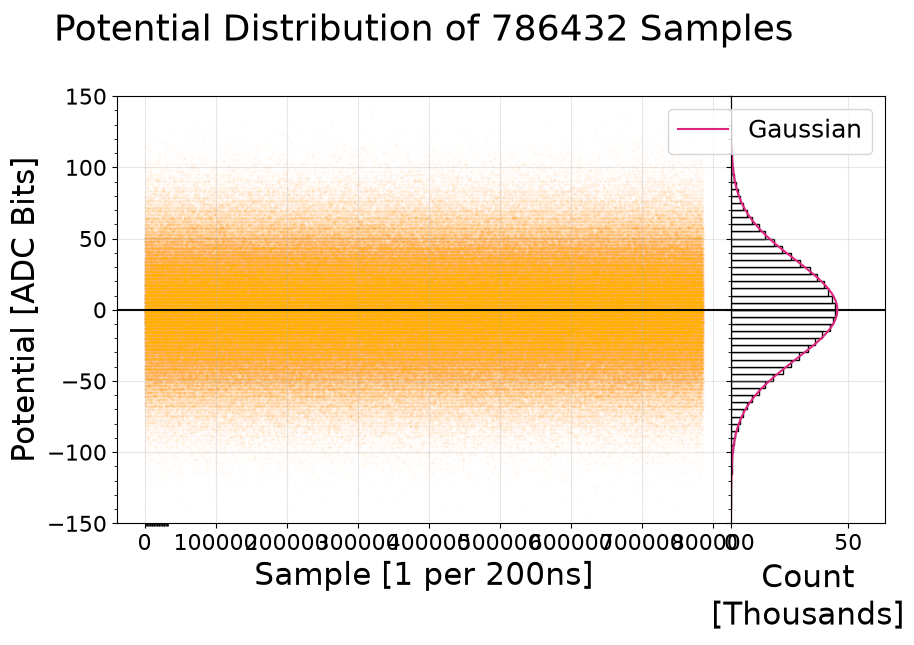

In [29]:
subspl = subspls[1]

fig, axs = plt.subplots(1, 2, sharey=True, width_ratios=(8, 2))
plt.subplots_adjust(left=0, right=1.2, top=1, wspace=0)
lin_range = np.arange(0, spl_size, 1)

axs[0].axhline(0, color='#080808')
axs[1].axhline(0, color='#080808')

axs[0].set_yticks(np.arange(-150, 150, 10), minor=True)
axs[0].set_xticks(np.arange(0, 34000, 1000), minor=True)

axs[0].scatter(lin_range, subspl, color='#FFB000', s=1, alpha=0.02)
axs[0].set_ylim(-150, 150)

axs[1].hist(subspl, bins=np.arange(-140, 140, 5), edgecolor='black', color='white', orientation="horizontal")

gauss_range = np.arange(-150, 151, 1)
axs[1].plot(stat.norm.pdf(gauss_range, loc=np.mean(subspl), scale=np.std(subspl))*10**6.6, gauss_range, 
        label="Gaussian", color="#DC267F")

axs[1].set_xlim(0, spl_size/12)

axs[1].xaxis.set_major_formatter(lambda x,y: int(x / 1000))

axs[0].set_title(f"Potential Distribution of {spl_size} Samples\n", fontsize=26)
axs[0].set_ylabel("Potential [ADC Bits]", fontsize=22)
axs[0].set_xlabel("Sample [1 per 200ns]", fontsize=22)

axs[1].set_xlabel("Count\n[Thousands]", fontsize=22)

axs[0].tick_params(labelsize=16)
axs[1].tick_params(labelsize=16)

axs[0].grid(alpha=0.3, zorder=-10)
axs[1].grid(alpha=0.3, zorder=-10)

axs[1].legend(fontsize=18, loc="upper right")



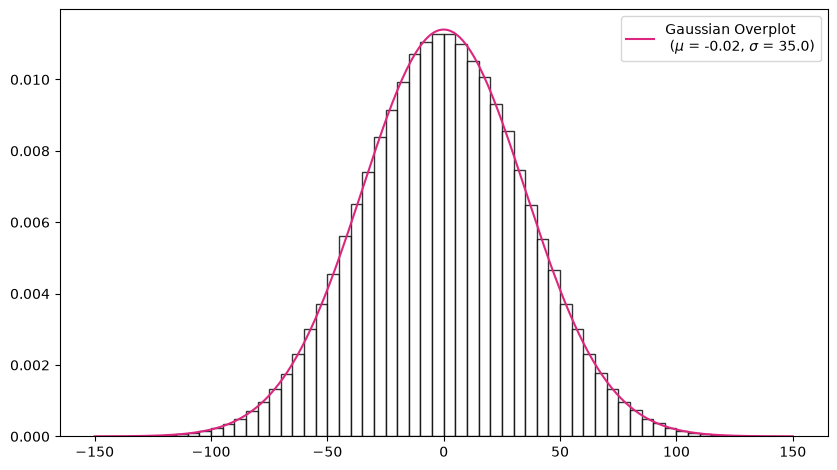

In [30]:
# Histogram only
fix, ax = plt.subplots(1, 1)
plt.subplots_adjust(left=0, right=1.2, top=1)

ax.hist(subspl, bins=np.arange(-150, 151, 5), edgecolor='black', color='white', alpha=0.8, density=True)

lin_range = np.arange(-150, 151, 1)
ax.plot(lin_range, stat.norm.pdf(lin_range, loc=np.mean(subspl), scale=np.std(subspl)), 
        label=f"Gaussian Overplot \n ($\mu$ = {np.round(np.mean(subspl), 2)}, $\sigma$ = {np.round(np.std(subspl), 2)})", color="#DC267F")
ax.legend()

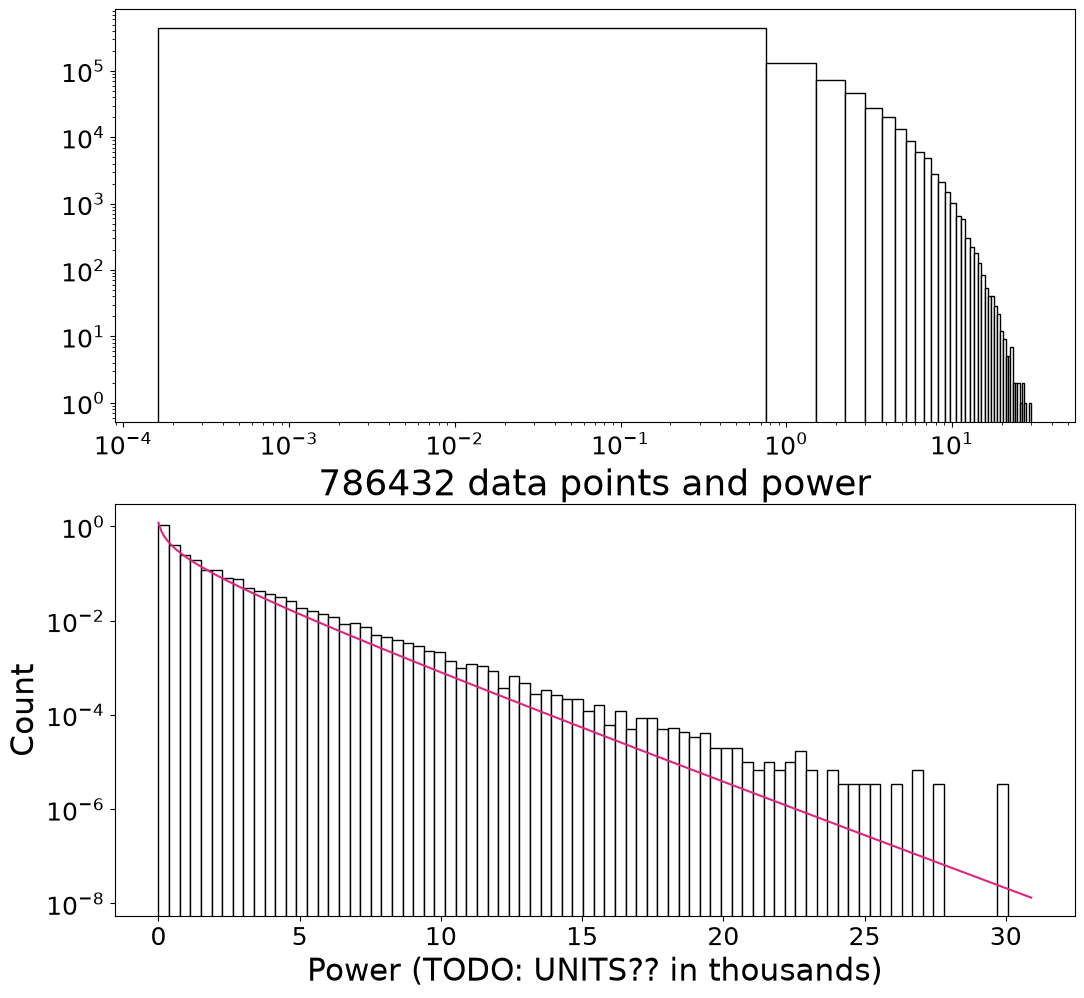

In [31]:
datasq = subspl ** 2 / 1000

datasq_range = np.arange(0, np.round(np.max(datasq)) + 1, 0.1)

fig, axs = plt.subplots(2, 1)
plt.subplots_adjust(left=0, right=1.5, top=2)

axs[0].hist(datasq, bins=40, edgecolor='black', color='white')
axs[0].loglog()
axs[0].tick_params(labelsize=18)

axs[1].hist(datasq, bins=80, edgecolor='black', color='white', density=True)
axs[1].plot(datasq_range, stat.chi2.pdf(datasq_range + 0.1, 1), color="#DC267F")
axs[1].semilogy()

#axs[1].set_ylim(0.5, 3000)

axs[1].set_xlabel("Power (TODO: UNITS?? in thousands)", fontsize=22)
axs[1].set_ylabel("Count", fontsize=22)
axs[1].set_title(f"{spl_size} data points and power", fontsize=26)
axs[1].tick_params(labelsize=18)

In [32]:
def adj_sum(data, ct):
    """
    Return NumPy array of ct-summed values from data. Length of array will be len(data) - (ct - 1).
    ct should be positive and non-zero.
    """
    adjs = []
    for i in range(len(data[ct-1:])):
        curr_sum = 0
        
        for j in range(i, i + ct):
            curr_sum += data[j]
        
        adjs.append(curr_sum)
    
    return np.array(adjs)

In [33]:
adj_cts = [1, 2, 4, 10, 100]

adj_sums = [adj_sum(datasq, i) for i in adj_cts]

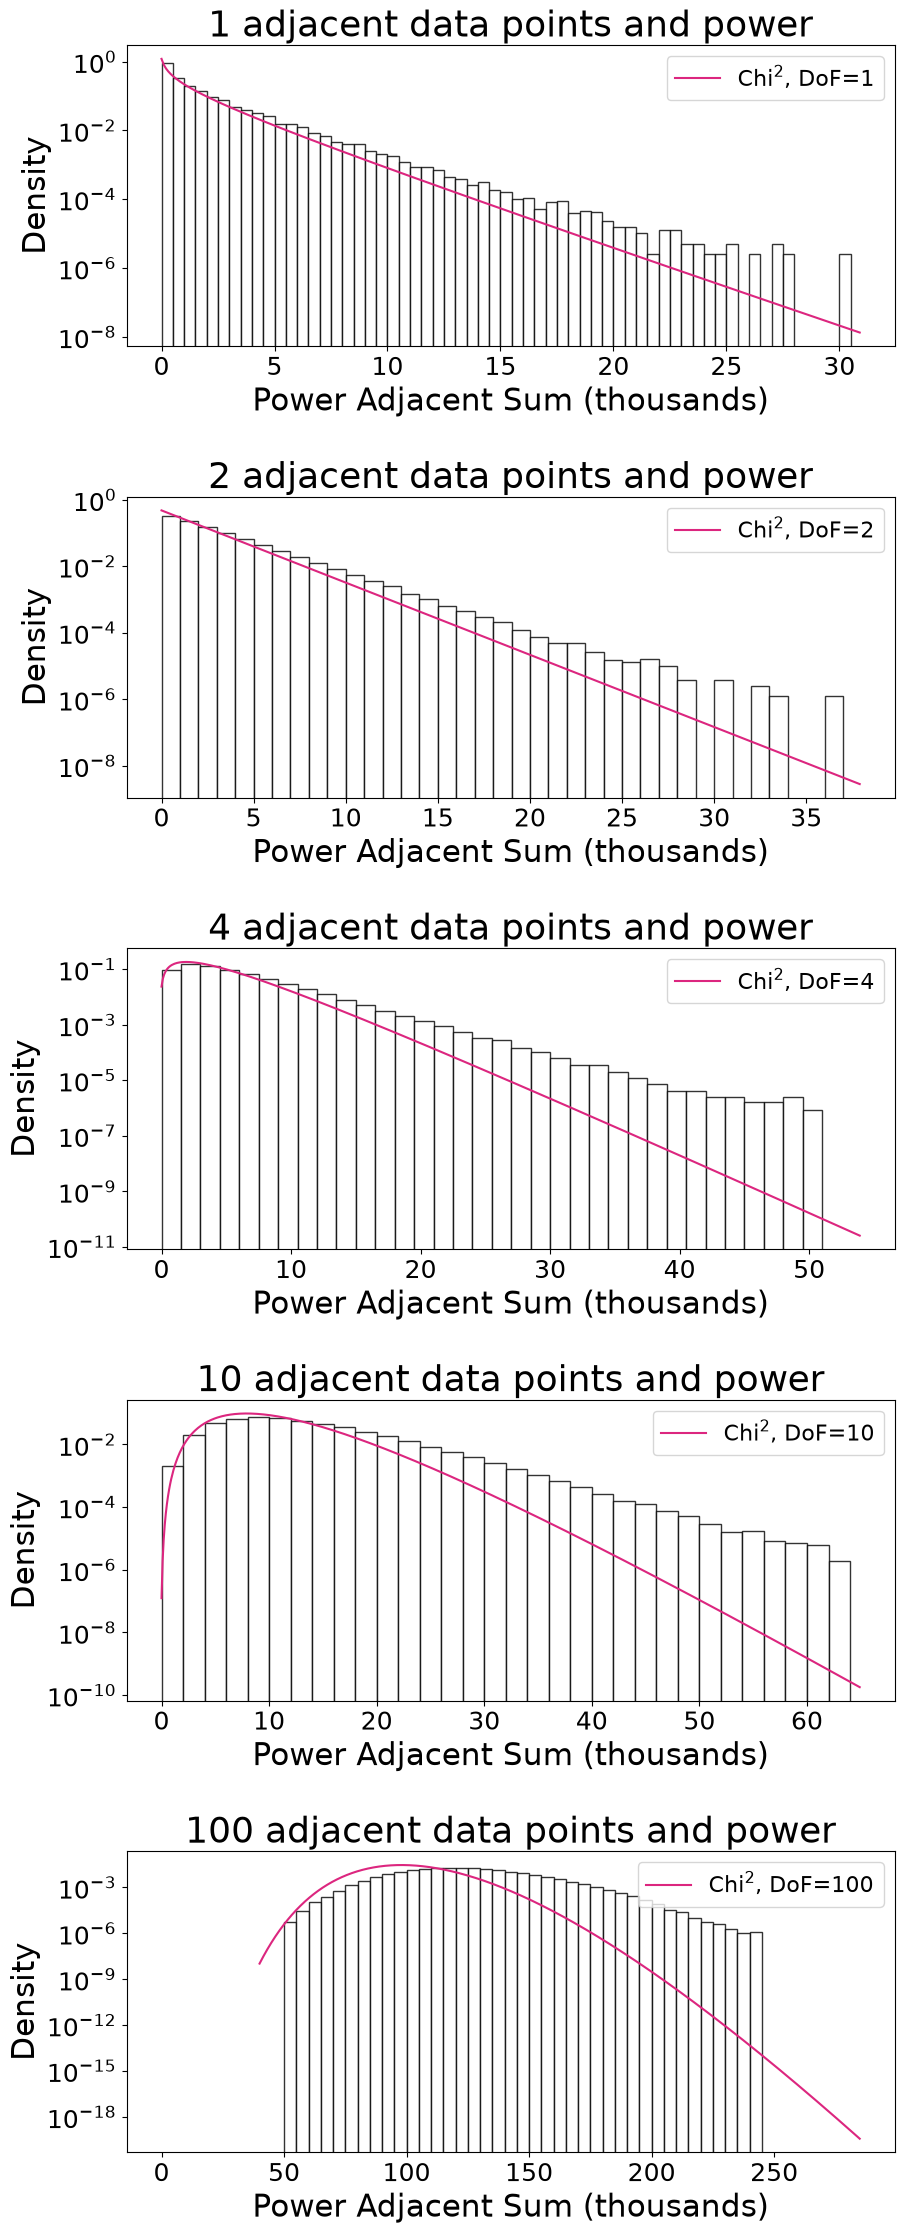

In [34]:
fig, axs = plt.subplots(5, 1)
plt.subplots_adjust(left=0, right=1.2, top=4.5, hspace=0.5)

i = 0

for ax in axs:    
    data_range = np.arange(0, np.round(np.max(adj_sums[i])) + 1, 0.1)
    
    ax.set_xlabel("Power Adjacent Sum (thousands)", fontsize=22)
    ax.set_ylabel("Density", fontsize=22)
    ax.set_title(f"{adj_cts[i]} adjacent data points and power", fontsize=26)
    ax.tick_params(labelsize=18)
    
    if i == len(adj_cts) - 1:
        data_range = np.arange(40, np.round(np.max(adj_sums[i])) + 40, 0.1)
        ax.plot(data_range, stat.chi2.pdf(data_range + 0.1, adj_cts[i]), label=f"Chi$^2$, DoF={adj_cts[i]}", color="#DC267F")
        #ax.set_xlim(50, 160)
        
        ax.hist(adj_sums[i], bins=np.arange(0, np.round(np.max(adj_sums[i]))+1, 5), edgecolor='black', color='white', density=True, alpha=0.8)

    else:
        ax.plot(data_range, stat.chi2.pdf(data_range + 0.1, adj_cts[i]), label=f"Chi$^2$, DoF={adj_cts[i]}", color="#DC267F")
        ax.hist(adj_sums[i], bins=np.arange(0, np.round(np.max(adj_sums[i]))+1, 0.5*(i+1)), edgecolor='black', color='white', density=True, alpha=0.8)
    
    ax.semilogy()
    ax.set_yticks([], minor=True)

    ax.legend(fontsize=16)
    #ax.set_ylim(1, 1000)
    #ax.set_xticks(np.arange(0, 20, 2))
    #ax.set_xticks(np.arange(0, 20, 0.5), minor=True)
    i += 1

In [34]:
fft_size = 2048

j = 0
subspl_cuts = []

while j < spl_size - fft_size:
    subspl_cuts.append(subspl[j:j+fft_size])
    j += fft_size

ffts = [] 

for spl in subspl_cuts:
    ffts.append(np.fft.fft(spl, n=fft_size))

powers = []

for fft in ffts:
    elems = []
    for elem in fft:
        elems.append(elem.real ** 2 + elem.imag ** 2)
    powers.append(elems)
    
powers = np.array(powers)

avg_power = np.mean(powers, axis=0)

Fractional uncertainty from Radiometer Equation: 0.00017736200269505306 [0.018%]


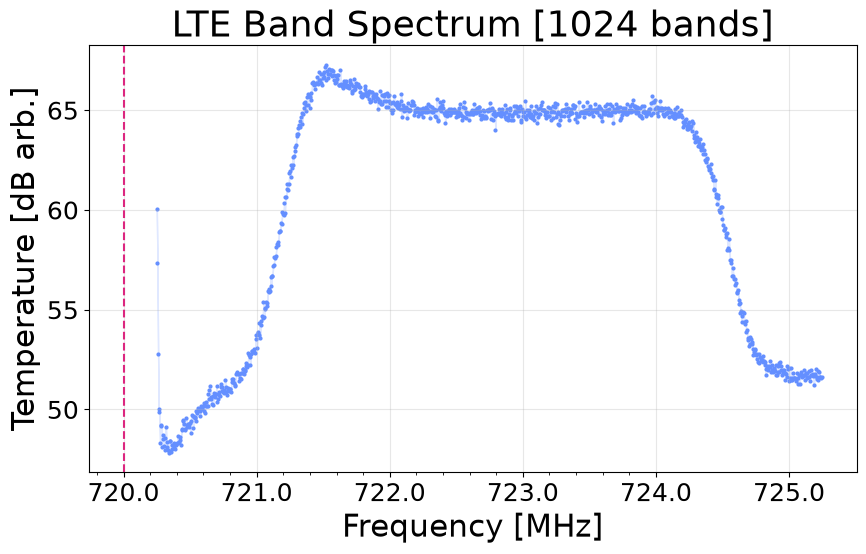

In [78]:
##########
# Variables from AirSpy setup
##########
spl_rate = 5000000
cadence = 1/spl_rate
LO = 719000000

##########
# Scatter (0) or Line (1)?
##########
line = False

# reflect LO change in AirSpy firmware
LO += (1/cadence)/4 

fig, ax = plt.subplots(1, 1)
plt.subplots_adjust(left=0, right=1.2, top=1)

lin_range = np.arange(LO, 1/cadence + LO, 1 / (cadence * fft_size/2))

if line:
    ax.plot(lin_range, 10*np.log10(avg_power[:fft_size//2]), color="#648FFF")
else:
    ax.scatter(lin_range, 10*np.log10(avg_power[:fft_size//2]), s=4, color="#648FFF")

ax.axvline(720000000, color="#DC267F", ls="--")

ax.set_xlabel("Frequency [MHz]", fontsize=22)
ax.set_ylabel("Temperature [dB arb.]", fontsize=22)
ax.set_title(f"LTE Band Spectrum [{fft_size//2} bands]", fontsize=26)

ax.set_xticks(np.arange(719000000, 724000000, 200000), minor=True)
ax.xaxis.set_major_formatter(lambda x,y: (x / 1000000))
ax.tick_params(labelsize=18)

ax.grid(alpha=0.3)

# radiometer equation (T \propto P)
time = spl_size * 200 * 10**(-9)
dv = 1 / (2 * cadence)

frac_radio = (time * cadence)**0.5
print(f"Fractional uncertainty from Radiometer Equation: {frac_radio} [{np.round(frac_radio * 100, 3)}%]")

# plot the fractional uncertainty
ax.fill_between(lin_range, 10*np.log10(avg_power[:fft_size//2]) - 10*np.log10(avg_power[:fft_size//2])*frac_radio,
                            10*np.log10(avg_power[:fft_size//2]) + 10*np.log10(avg_power[:fft_size//2])*frac_radio,
                            color="#648FFF", alpha=0.2)